In [144]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from utils import wasserstein

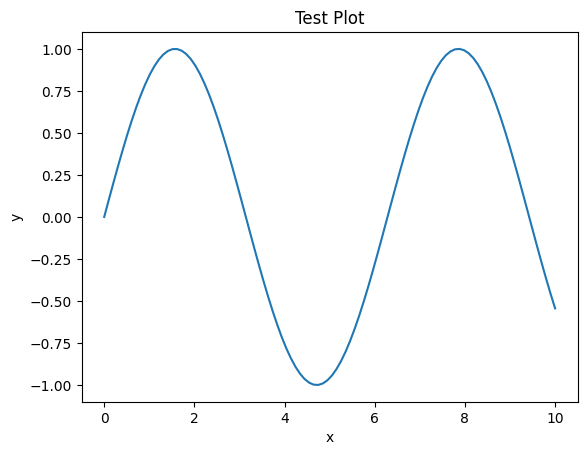

In [145]:
def test():
    x = np.linspace(0, 10, 100)
    y = np.sin(x)

    plt.plot(x, y)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Test Plot')
    plt.show()

test()

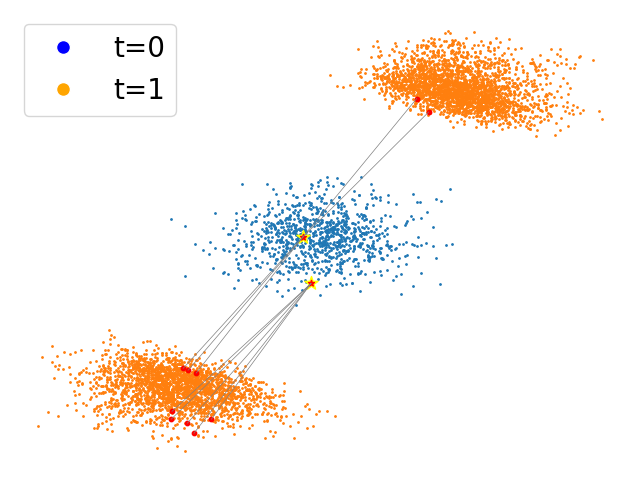

In [146]:
import random
seed = 3407
np.random.seed(seed)
random.seed(seed)
n_samples = 1000
batch_size = 1000
t = 1
nu = 0.3
mix= 0.5
dim = 2
x = np.random.randn(n_samples, dim)
x_labels = np.arange(1000)
dot = np.dot(x, [1, 2])
dot
y = []
for _ in range(5):
      sg = np.sign(dot + mix * np.random.randn(n_samples,))
      v = np.repeat([[3, 6]], repeats=1000, axis=0)
      y_tmp = x + sg.reshape(-1, 1) * v + np.sqrt(t) * nu * np.random.randn(n_samples, dim)
      y.append(y_tmp)
y = np.concatenate(y, axis=0)
y_labels = np.concatenate([x_labels] * 5, axis=0)

fig, ax = plt.subplots(figsize=(8, 6))
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([]) 
ax.set_yticks([])
ax.set_xticklabels([]) 
ax.set_yticklabels([])  

plt.scatter(x[:,0], x[:,1],  s=1)
plt.scatter(y[:,0], y[:,1],  s=1)

t = 6
x0 = x[t, :]
y0 = np.array([y[t + 1000*k, :] for k in range(5)])
for k in range(5):
      yk = y[t + 1000*k, :]
      plt.plot([x0[0], yk[0]], [x0[1], yk[1]], lw = 0.5, c='grey')
plt.scatter([x0[0]], [x0[1]], marker='*', s=100, c='yellow')
plt.scatter([x0[0]], [x0[1]], marker='*', s=20, c='red')
plt.scatter(y0[:,0], y0[:,1], c='r', s=10)


t = 7
x0 = x[t, :]
y0 = np.array([y[t + 1000*k, :] for k in range(5)])
for k in range(5):
      yk = y[t + 1000*k, :]
      plt.plot([x0[0], yk[0]], [x0[1], yk[1]], lw = 0.5, c='grey')
plt.scatter([x0[0]], [x0[1]], marker='*', s=100, c='yellow')
plt.scatter([x0[0]], [x0[1]], marker='*', s=20, c='red')
plt.scatter(y0[:,0], y0[:,1], c='r', s=10)

from matplotlib.lines import Line2D  
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=10, label='t=0'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=10, label='t=1')
]

ax.legend(handles=legend_elements, loc='best', fontsize=20)
plt.savefig('syn_dataset.png', bbox_inches='tight')
plt.show()



In [147]:
y_label_dic = {}
for i in range(len(y_labels)):
    if y_labels[i] not in y_label_dic:
        y_label_dic[y_labels[i]] = []
    y_label_dic[y_labels[i]].append(i)

y_label_dic

{0: [0, 1000, 2000, 3000, 4000],
 1: [1, 1001, 2001, 3001, 4001],
 2: [2, 1002, 2002, 3002, 4002],
 3: [3, 1003, 2003, 3003, 4003],
 4: [4, 1004, 2004, 3004, 4004],
 5: [5, 1005, 2005, 3005, 4005],
 6: [6, 1006, 2006, 3006, 4006],
 7: [7, 1007, 2007, 3007, 4007],
 8: [8, 1008, 2008, 3008, 4008],
 9: [9, 1009, 2009, 3009, 4009],
 10: [10, 1010, 2010, 3010, 4010],
 11: [11, 1011, 2011, 3011, 4011],
 12: [12, 1012, 2012, 3012, 4012],
 13: [13, 1013, 2013, 3013, 4013],
 14: [14, 1014, 2014, 3014, 4014],
 15: [15, 1015, 2015, 3015, 4015],
 16: [16, 1016, 2016, 3016, 4016],
 17: [17, 1017, 2017, 3017, 4017],
 18: [18, 1018, 2018, 3018, 4018],
 19: [19, 1019, 2019, 3019, 4019],
 20: [20, 1020, 2020, 3020, 4020],
 21: [21, 1021, 2021, 3021, 4021],
 22: [22, 1022, 2022, 3022, 4022],
 23: [23, 1023, 2023, 3023, 4023],
 24: [24, 1024, 2024, 3024, 4024],
 25: [25, 1025, 2025, 3025, 4025],
 26: [26, 1026, 2026, 3026, 4026],
 27: [27, 1027, 2027, 3027, 4027],
 28: [28, 1028, 2028, 3028, 4028],
 29: 

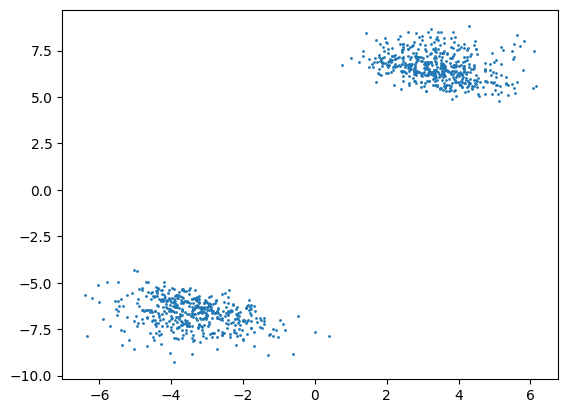

In [148]:
def sample(x_labels, y_label_dic, y):
    idx = [random.choice(y_label_dic[i]) for i in x_labels]
    return np.take(y, idx, axis=0)
sam_y = sample(x_labels, y_label_dic, y)
plt.scatter(sam_y[:,0], sam_y[:,1], s=1)

In [ ]:
import torch
import torch.nn as nn

class ToyModel(nn.Module):
    def __init__(self, dim, latent_dim, encoder_dims, decoder_dims):
        super(ToyModel, self).__init__()
        self.dim = dim
        self.latent_dim = latent_dim
        self.encoder_dims = encoder_dims
        self.decoder_dims = decoder_dims

        encoder_blocks = [nn.Linear(dim, encoder_dims[0]), nn.ReLU()]
        for i in range(len(encoder_dims)-1):
            encoder_blocks.append(nn.Linear(encoder_dims[i], encoder_dims[i+1]))
            encoder_blocks.append(nn.ReLU())
        encoder_blocks.append(nn.Linear(encoder_dims[-1], latent_dim*2))
        self.encoder_x = nn.Sequential(*encoder_blocks)

        encoder_blocks = [nn.Linear(dim * 2, encoder_dims[0]), nn.ReLU()]
        for i in range(len(encoder_dims)-1):
            encoder_blocks.append(nn.Linear(encoder_dims[i], encoder_dims[i+1]))
            encoder_blocks.append(nn.ReLU())
        encoder_blocks.append(nn.Linear(encoder_dims[-1], latent_dim*2))
        self.encoder_y = nn.Sequential(*encoder_blocks)

        decoder_blocks = [nn.Linear(latent_dim + dim + 2, decoder_dims[0]), nn.ReLU()]
        for i in range(len(decoder_dims)-1):
            decoder_blocks.append(nn.Linear(decoder_dims[i], decoder_dims[i+1]))
            decoder_blocks.append(nn.ReLU())
        decoder_blocks.append(nn.Linear(decoder_dims[-1], dim))
        self.decoder_net = nn.Sequential(*decoder_blocks)

    def encode(self, y, x):
        output = self.encoder_x(x)
        latent_x = output[:, :self.latent_dim]
        logvar_x = output[:, self.latent_dim:]
        output = self.encoder_y(torch.cat([y, x], dim=1))
        latent_y = output[:, :self.latent_dim]
        logvar_y = output[:, self.latent_dim:]
        return latent_x, logvar_x, latent_y, logvar_y

    def forward(self, x, latent, r, t):
        ipt = torch.cat([x, latent, r.view(-1, 1), t.view(-1, 1)], dim=1)
        return self.decoder_net(ipt)
    
    def loss(self, x, r, t, y):
        mu_x, logvar_x, mu_y, logvar_y = self.encode(y, x)
        kl_loss_regular = torch.mean(mu_x**2) + 3 * (- torch.mean(logvar_x) + torch.mean(torch.exp(logvar_x) ) - 1)
        kl_loss_xy = (torch.mean((mu_y-mu_x)**2) - torch.mean(logvar_y-logvar_x) + torch.mean(torch.exp(logvar_y) / torch.exp(logvar_x) ) - 1)
        
        start = r * y + (1-r) * x
        end = t * y + (1-t) * x
        v = y - x
        latent = mu_y + torch.exp(logvar_y/2) * torch.randn_like(mu_y)
        ipt = torch.cat([start, latent, r.view(-1, 1), t.view(-1, 1)], dim=1)
        tangent = torch.cat([v, torch.zeros_like(latent), torch.ones_like(r), torch.ones_like(t)], dim=1)
        u, jvp = torch.func.jvp(self.decoder_net, (ipt, ), (tangent, ))
        jvp = jvp.detach()
        v_loss = torch.mean((u - v - (t-r) * jvp)**2)
        return {
            'v_loss': v_loss,
            'kl_loss_xy': kl_loss_xy,
            'kl_loss_regular': kl_loss_regular,

        }
    
    def simulation(self, x, use_x=False, y = None, r=0, t=1):
        if use_x:
            output = self.encoder_x(x)
            mu = output[:, :self.latent_dim]
            logvar = output[:, self.latent_dim:]
            latent = mu + torch.exp(logvar/2) * torch.randn_like(mu)
        elif y != None:
            print('hello')
            output = self.encoder_y(torch.cat([y, x], dim=1))
            mu = output[:, :self.latent_dim]
            logvar = output[:, self.latent_dim:]
            latent = mu + torch.exp(logvar/2) * torch.randn_like(mu)
        else:
            latent = torch.randn(x.shape[0], self.latent_dim)
        batch, dim = x.shape
        r = torch.ones((batch, 1)) * r
        t = torch.ones((batch, 1)) * t
        return x + self.decoder_net(torch.cat([x, latent, r, t], dim=1)) * (t-r)


In [150]:
torch.manual_seed(seed)
toy_model = ToyModel(dim, 2, [32, 64, 32], [32, 64, 32])
x = torch.tensor(x, dtype=torch.float32)
optimizer = torch.optim.Adam(toy_model.parameters(), lr=1e-3)
for step in range(5000):
    yy = torch.tensor(sample(x_labels, y_label_dic, y), dtype=torch.float32)
    tt = torch.rand((batch_size, 1))
    rr = torch.rand((batch_size, 1))
    r = torch.minimum(tt, rr)
    t = torch.maximum(tt, rr)
    optimizer.zero_grad()
    loss = toy_model.loss(x, r, t, yy)
    if step % 100 == 0:
        print(loss)
    loss = 1 * loss['v_loss'] + 1 * loss['kl_loss_xy'] + 10 * loss['kl_loss_regular']
    loss.backward()
    optimizer.step()

{'v_loss': tensor(22.6293, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(0.1348, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0131, grad_fn=<AddBackward0>)}
{'v_loss': tensor(4.7984, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(1.6400, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0097, grad_fn=<AddBackward0>)}
{'v_loss': tensor(2.3276, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(1.0672, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0032, grad_fn=<AddBackward0>)}
{'v_loss': tensor(0.6518, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(0.9030, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0026, grad_fn=<AddBackward0>)}
{'v_loss': tensor(4.6038, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(0.6342, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0022, grad_fn=<AddBackward0>)}
{'v_loss': tensor(8.1503, grad_fn=<MeanBackward0>), 'kl_loss_xy': tensor(0.5087, grad_fn=<SubBackward0>), 'kl_loss_regular': tensor(0.0021, grad_fn=<AddBackward0>)}
{'v_loss'

([0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0050000000000000044,
  0.01200000000000001,
  0.043999999999999984,
  0.14100000000000001,
  0.274,
  0.473,
  0.719,
  0.863,
  0.95,
  0.984,
  0.997,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0],
 [9.865876450376946e-10,
  3.332044848542845e-08,
  7.933281519755892e-07,
  1.334574901590634e-05,
  0.00015910859015753396,
  0.0013498980316300933,
  0.008197535924596114,
  0.03593031911292576,
  0.11506967022170828,
  0.27425311775007355,
  0.5,
  0.7257468822499266,
  0.8849303297782918,
  0.9640696808870742,
  0.9918024640754038,
  0.9986501019683699,
  0.9998408914098424,
  0.9999866542509841,
  0.999999206671848,
  0.9999999666795515,
  0.9999999990134123],
 0.1212517173670029)

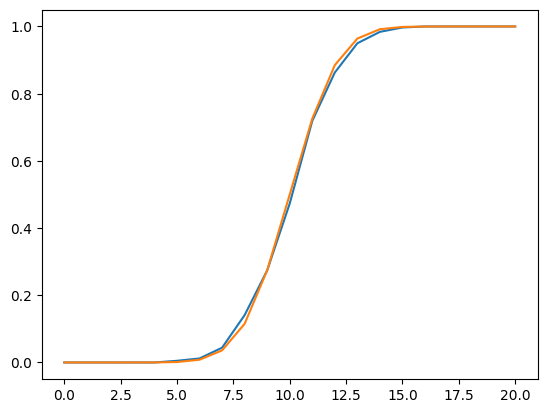

In [ ]:
from scipy.stats import norm
lis = []
stand = []

for k in range(21):
    t = -1 + k / 10
    yyy = toy_model.simulation(t*torch.ones((batch_size, dim)), use_x=True).detach()

    prob = norm.sf(-t * 3 / mix)
    yyy.numpy()
    ans = (np.sign(yyy.numpy().dot([1,2])).sum() / batch_size)/2 + 0.5
    lis.append(ans)
    stand.append(prob)

plt.plot(lis)
plt.plot(stand)

lis, stand, np.sum(np.abs(np.array(lis) - np.array(stand)))

In [152]:
m = 0
yyy = toy_model.simulation(x, use_x=True).detach()
m = wasserstein(yyy, torch.tensor(y, dtype=torch.float32))
print(m)

0.2659377780819308
